# Ayudantía N°6:
### **Análisis de datos categóricos**
- Análisis univariado: Distribución de frecuencia: Tablas de frecuencia
- Análisis bivariado: Cruce de variables: Tablas de contingencia


## Antes de comenzar: trabajar con archivos en Google Colab

Esta ayudantía está preparada para ejecutarse en **Google Colab utilizando el entorno de ejecución de R**

Primero, sube a Colab el archivo:

`base_antropologia_limpia.xlsx`

Puedes hacerlo ejecutando la siguiente celda y seleccionando el archivo que descargaste en la página del curso desde tu computador

- Ruta:
/content/base_antropologia_limpia.xlsx

### 1. Cargar Paquetes


In [ ]:
system("apt-get update && apt-get install -y libmagick++-dev", intern = TRUE)
install.packages("summarytools") #Para no tener problemas con

In [ ]:
if (!require("pacman")) install.packages("pacman")
pacman::p_load(tidyverse,# Universo de paquetes : tidyr, dplyr, ggplot2,readr,purrr,tibble, stringr, forcats
               openxlsx,#Leer archivos xlsx
               readxl,#Leer archivos xl
               writexl,#Guardar tablas formato excel
               DataExplorer,#Exploración rápida
               summarytools,#Contiene la función freq() que muestra las frecuencias absolutas y relativas de una variable
               kableExtra,#Tablas elegantes
               webshot2,#Exportar tablas
               knitr,#Dar formato a las tablas
               gt, #Dar formato a las tablas
               gmodels)

### 2. Importar base de datos


In [ ]:
base <- read.xlsx("/content/base_antropologia_limpia.xlsx")

### 3. Explorar base


In [ ]:
glimpse(base)

In [ ]:
names(base)

# **Tablas de distribución de frecuencias**
### Quiero saber ¿cuántas personas se identifican con cada género?
- Variable de interés: identidad de género recodificada _r


### Tabla simple con `table()`


In [ ]:
table(base$identidad_genero_r)

### Distintas formas de hacer tablas de frecuencia:


# Forma 1: Con `freq()` de summarytools ####


In [ ]:
freq(base$identidad_genero_r)

La tabla está algo desordenada: incluye frecuencias válidas y acumuladas por default, y aparecen los NA


In [ ]:
# Filtramos los NA de forma directa y quitamos la fila <NA> del resultado
tabla_genero <- freq(base$identidad_genero_r[!is.na(base$identidad_genero_r)], prop = TRUE, order = "freq", report.nas = FALSE)

# Filtramos la fila <NA> del resultado final usando una exclusión simple por nombre
tabla_genero[rownames(tabla_genero) != "<NA>", ]

Si queremos además visualizar una tabla más elegante y formateada
Tabla formateada con `kable` (para formato HTML)


In [ ]:
# 1. Generar la tabla de frecuencias de la variable identidad de género
tabla_genero_limpia <- freq(base$identidad_genero_r[!is.na(base$identidad_genero_r)], prop = TRUE, order = "freq", report.nas = FALSE)

# 2. Dar formato HTML a la tabla usando kableExtra
tabla_html_limpia <- tabla_genero_limpia %>%
  tb() %>%
  filter(tolower(as.character(.[, 1])) != "<na>") %>%
  kable(col.names = c("Género", "Frecuencia", "%", "% Acumulado"),
        caption = "Distribución de frecuencias de Género (Sin Valores Nulos)",
        digits = c(0, 0, 2, 2),
        format = "html") %>%
  kable_classic(full_width = FALSE, html_font = "Cambria")

# 3. Guardar la tabla en formato HTML dentro de la carpeta tablas
if(!dir.exists("tablas")) dir.create("tablas")
save_kable(tabla_html_limpia, "tablas/f_genero_limpia.html")

# Mostrar la tabla formateada en el notebook
tabla_html_limpia

In [ ]:
base %>%
  freq(identidad_genero_r, prop = TRUE, order = "freq", report.nas =  FALSE)%>%
  tb() %>%  #hace que se visualice
  kable(col.names = c("Género", "Frecuencia", "%", "% Acumulado"), #nombro las columnas
        caption = "Distribución de frecuencias de Género", #nombro la tabla
        digits = c(0, 0, 2, 2))%>%  #establezco decimales por columna
  kable_classic(full_width = F, html_font = "Cambria") #la tabla no debe ocupar todo el ancho, fuente cambria


In [ ]:
# Colab está imprimiendo el código HTML crudo en vez de interpretarlo y renderizarlo como una tabla visual
# Renderizamos el código HTML para que se vea como tabla formateada en Colab
IRdisplay::display_html(as.character(tabla_html_limpia))

### Guardar la tabla en formato HTML

In [ ]:
#Cargar librerías necesarias
library(knitr)
library(kableExtra)

### Crear tabla


In [ ]:
tabla_html <- base %>%
  freq(identidad_genero_r, prop = TRUE, order = "freq", report.nas = FALSE) %>%
  tb() %>%
  kable(col.names = c("Género", "Frecuencia", "%", "% Acumulado"),
        caption = "Distribución de frecuencias de Género",
        digits = c(0, 0, 2, 2),
        format = "html") %>%
  kable_classic(full_width = FALSE, html_font = "Cambria")


### Creamos carpeta si no existe


In [ ]:
if(!dir.exists("tablas")) dir.create("tablas")
# La carpeta que creamos llamada "tablas" se ha guardado directamente en el directorio de trabajo actual de la sesión de Google Colab

In [ ]:
# Acceso directo mejorado y seguro para descargar archivos de la carpeta 'tablas'
archivos <- list.files("tablas", full.names = TRUE)

if (length(archivos) == 0) {
  cat("La carpeta 'tablas' está vacía o aún no se han generado archivos.\n")
} else {
  cat("=== ENLACES DE DESCARGA DIRECTA ===\n")
  for (archivo in archivos) {
    nombre_archivo <- basename(archivo)
    ext <- tools::file_ext(nombre_archivo)

    # Determinar el tipo MIME correcto para la descarga
    mime <- switch(ext,
      "html" = "text/html",
      "xlsx" = "application/vnd.openxmlformats-officedocument.spreadsheetml.sheet",
      "png"  = "image/png",
      "application/octet-stream"
    )

    # Leer el archivo en binario y codificarlo en Base64 de manera segura
    con <- file(archivo, "rb")
    bytes <- readBin(con, "raw", n = file.info(archivo)$size)
    close(con)

    base64_data <- jsonlite::base64_enc(bytes)

    # Generar un botón de descarga HTML nativo y seguro que no requiere conexión externa
    html_button <- sprintf(
      '<p style="margin: 8px 0;">📂 <a href="data:%s;base64,%s" download="%s" style="background-color: #1a73e8; color: white; padding: 6px 12px; text-decoration: none; border-radius: 4px; font-weight: bold; display: inline-block; font-size: 13px; box-shadow: 0 1px 3px rgba(0,0,0,0.2);">Descargar %s</a></p>',
      mime, base64_data, nombre_archivo, nombre_archivo
    )

    IRdisplay::display_html(html_button)
  }
}

### Guardar como archivo HTML


In [ ]:
save_kable(tabla_html, "tablas/f_genero1.html")

# Aún no existe la tabla como un archivo independiente en el computador, sino que creamos su diseño dentro de la memoria temporal de R
# Con esta función podemos exportar y materializar esa tabla que está en la memoria y escribirla físicamente en el almacenamiento como un archivo .html o una imagen .png

### Pasos para ver la carpeta "tablas" y los archivos guardados en google colab:

- 1. Ve a la barra lateral izquierda de tu pantalla en Google Colab.
- 2. Haz clic en el ícono de la Carpeta (📁) para abrir el explorador de archivos.
- 3. Verás una carpeta llamada tablas

## En formato Excell
Guardamos la tabla sin utilizar Kable

* Creamos la tabla como **data.frame**


In [ ]:
f_genero1_df <- base %>%
  freq(identidad_genero_r, prop = TRUE, order = "freq", report.nas = FALSE) %>%
  tb() %>%
  rename(Género = 1, Frecuencia = 2, Porcentaje = 3, Porcentaje_acumulado = 4) %>%
  mutate(Porcentaje = round(Porcentaje, 2),
         Porcentaje_acumulado = round(Porcentaje_acumulado, 2))

Guardamos como archivo Excel correctamente

In [ ]:
write.xlsx(f_genero1_df, "tablas/f_genero1.xlsx")

Si quieres mostrarla bonita en pantalla ahora sí usas kable:


In [ ]:
f_genero1_df %>%
  kable(col.names = c("Género", "Frecuencia", "%", "% Acumulado"),
        caption = "Distribución de frecuencias de Género",
        digits = c(0, 0, 2, 2)) %>%
  kable_classic(full_width = F, html_font = "Cambria")

In [ ]:
# Esto funciona bien directamente en Rtudio, pero acá en Colab habrá que utilizar IRdisplay

# Forma 2: con tidyverse
Con este código vamos a generar una tabla de frecuencias y porcentajes de la variable identidad de género.
Este proceso incluye: filtrar valores perdidos, contar frecuencias, calcular porcentajes,
redondear decimales, ordenar los resultados, renombrar columnas y agregar una fila de Total.


In [ ]:
f_genero2 <- base %>%
  filter(!is.na(identidad_genero_r)) %>% # filtramos para eliminar los casos con NA (sin respuesta)
  count(identidad_genero_r) %>% # contamos cuántas veces aparece cada categoría de identidad de género
  mutate(Porcentaje = n / sum(n) * 100) %>% # generamos el porcentaje respecto del total
  mutate(Porcentaje = round(Porcentaje, 2)) %>% # redondeamos los porcentajes a dos decimales
  arrange(desc(Porcentaje)) %>% # ordenamos los resultados de mayor a menor porcentaje
  rename(Frecuencia = n, Genero = identidad_genero_r) %>% # renombramos las columnas para mayor claridad
  bind_rows(list(Genero = "Total", Frecuencia = sum(.$Frecuencia), Porcentaje = 100))

Agregamos una fila final que indica el total de respuestas, con 100% como porcentaje
La función bind_rows nos permite agregar una fila de Total al final, lo que facilita la lectura.


### Exportamos la tabla a Excel en la carpeta "tablas" que creamos antes


In [ ]:
write.xlsx(f_genero2, "tablas/f_genero2.xlsx")

### Exportamos la tabla a HTML en la carpeta "tablas"


In [ ]:
library(kableExtra)

### Crear la tabla HTML


In [ ]:
tabla_html <- f_genero2 %>%
  kable(format = "html",
        col.names = c("Género", "Frecuencia", "Porcentaje"),
        caption = "Distribución de identidades de género",
        digits = c(0, 0, 2)) %>%
  kable_classic(full_width = FALSE, html_font = "Cambria")

### Guardar como archivo HTML

In [ ]:
save_kable(tabla_html, file = "tablas/f_genero2.html")

# **Tablas de contingencia (cruce 2 variables)**


In [ ]:
#Cargar las bibliotecas necesarias
library(knitr)
library(kableExtra)
library(webshot2)
library(gmodels)

# Forma 1: Mediante `ctable()`


### a) Elegir nuestras variables para el cruce y hacer la tabla con estas

Si nos preguntamos
*¿Qué religiones son más frecuentes en ciertos colegios?*

Esta tabla de contingencia presenta **la distribución de las afiliaciones religiosas según el último colegio**

* Cómo varía o se mantiene la proporción de religiones en los diferentes colegios.

  - Variables: `ultimo_colegio` y `re_02`(afiliación religiosa)


## Tabla de contingencia simple


Nos entrega:
- frecuencias absolutas (conteo de casos por combinación)
- Proporciones marginales (por fila y columna)
- Totales por fila y por columna


In [ ]:
summarytools::ctable( x = base$re_02, y = base$ultimo_colegio)

Podemos ver que queda una tabla desordenada y compleja de entender

### Obtener **proporciones** por columna:


#### Indica que las **proporciones deben calcularse por columna** ("column-wise proportions")

Esto es útil cuando quieres analizar cómo se distribuyen las respuestas dentro de cada columna

- Por ejemplo, qué proporción de estudiantes de colegio particular pertenece a cada religión

  - justify = "l" alinea el texto a la izquierda dentro de la tabla ("l" de left)


In [ ]:
ctable( x = base$re_02, y = base$ultimo_colegio, prop = "c", justify = "l")

Nos damos cuenta de que la tabla, si bien es entendible, tiene mucha información, muchas categorías, por lo que es compleja de entender

### b) Recodificamos las categorías para dejar menos cantidad de categorías de respuesta con MUTATE
- Para la variable `re_02`


In [ ]:
#Vemos categorías de respuesta de re_02
unique(base$re_02)

### Recodificamos categorías con mutate


In [ ]:
base <- base %>%
  mutate(re_02 = case_when(re_02 ==  "Yoruba " ~ "Otra",
                           re_02 ==  "Grecorromana " ~ "Otra",
                           re_02 ==  "Grecorromana" ~ "Otra",
                           re_02 ==  "Ortodoxo" ~ "Ortodoxa",
                           re_02 ==  "Cristianismo Protestante (Evangélico, anglicano, etcétera)" ~ "Cristianismo protestante",
                           re_02 ==  "No tengo afiliaciones religiosas y tampoco me adscribo a ningún tipo de corriente de pensamiento de tipo clasificatoria" ~ "Ninguna",
                           re_02 ==  "Catolico" ~ "Catolicismo",
                           re_02 ==  "deísmo" ~ "Deísmo",
                           re_02 ==  "Agnóstico" ~ "Agnóstico/a",
                           re_02 ==  "Ateo" ~ "Ninguna",
                           re_02 ==  "Ninguno " ~ "Ninguna",
                           re_02 ==  "Pagana" ~ "Otra",
                           re_02 ==  "No tengo una afiliación religiosa, pero si me considero una persona espiritual (por ejemplo, creo en las energías)." ~ "Otra",
                           re_02 ==  "seria en creer en alguien superior un tipo de energía que se interpreta de diversas formas en la religión pero no es alguien al cual se le pueda poner un nombre" ~ "Otra",
                           TRUE ~ re_02))


### Verificamos


In [ ]:
unique(base$re_02)

### c) Filtramos NA y Ordenamos
En este caso no será necesario pues no hay valores NA


### Para ordenar categorías...

In [ ]:
#Observamos el tipo de variable
class(base$re_02)

Es una variable **character**, pero debemos transformarla a variable **factor** para poder ordenarla


In [ ]:
#Transformamos a factor
base <- base %>%
  mutate(re_02 = as.factor(re_02))

In [ ]:
#Ordenamos categorías
base$re_02 <- base$re_02 %>% fct_relevel(c("Catolicismo", "Cristianismo protestante",
                                           "Agnóstico/a", "Ninguna", "Otra"))

### Verificamos


In [ ]:
unique(base$re_02)

Fíjense en el levels


### d) Crear la tabla cruzada con `ctable`


In [ ]:
ctable(x = base$re_02,
       y = base$ultimo_colegio,
       prop = "c", #proporciones por columna
       justify = "l") #texto hacia la izquierda

### e) Interpretar
- El grupo "Otra" es el más común en todos los tipos de colegio, especialmente en el subvencionado (45%)
- Los colegios particulares tienen más personas sin religión ("Ninguna"): 28,6%
- Los colegios públicos tienen un poco más de agnósticos (25,6%).
Las religiones institucionales (católica y protestante) no superan juntas el 12% en ningún tipo de colegio


# Forma 2: Mediante `prop.table()`
### a) Elegir nuestras variables para el cruce y hacer la tabla con estas
Si nos preguntamos ¿Qué religiones predominan en ciertos estratos de clase?
la tabla muestra cómo se distribuyen las afiliaciones religiosas según la clase social
- Variables: `clase_social` y `re_01`


### b) Crear la tabla y guardarla el objeto (si fuera RStudio quedaría guardada en el enviroment)


In [ ]:
tabla_rel_clase <- base  %>%
  select(Religión = re_01, `Clase Social` = clase_social) %>%  # Seleccionar y renombrar las variables
  droplevels() %>% # Eliminar las categorías que no se utilizan en la columna
  table(.) %>%# Hacer una tabla con todos los datos
  addmargins(.,2) %>% # Calcular los porcentajes por columnas
  prop.table(.) %>% # Agregar total de columnas
  round(4)*100  # Formatear y redondear con símbolo de porcentaje

### c) Interpretar y sacar conclusiones


: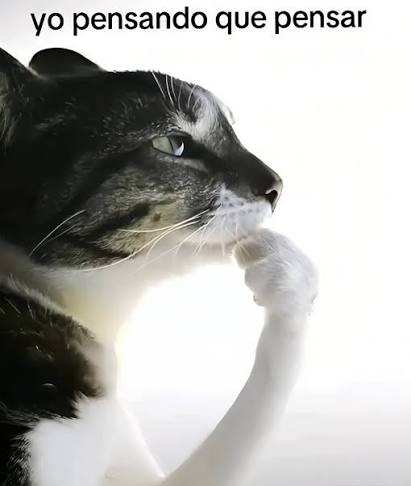

### d) Guardar en un excel


In [ ]:
write.xlsx(tabla_rel_clase, "tablas/tabla_rel_clase.xlsx")

### e) Guardar en PNG


In [ ]:
tabla_rel_clase %>%
  kable(., caption="Tabla de contingencia para religión y clase social (% por columnas)") %>%
  kable_classic(full_width = F, html_font = "Cambria", font_size = 15) %>%
  save_kable(file = "tablas/tabla_rel_clase.png", zoom = 2)